# COCO 2017 Dataset — Structure Overview

## Top-level folders (folders in base_path)

| Folder | Contents | Count |
|---|---|---|
| `train2017` | Training images | 118,287 |
| `val2017` | Validation images | 5,000 |
| `test2017` | Test images (no public annotations) | 40,670 |
| `annotations` | JSON annotation files for train/val | 6 files |

## Annotation files (what each one is for) -

| File | Task it supports |
|---|---|
| `instances_train2017.json` & `instances_val2017.json` | Object detection & segmentation — bounding boxes + pixel masks for 80 object categories (person, car, dog, etc.) |
| `person_keypoints_train2017.json` & `person_keypoints_val2017.json` | Human pose estimation — (x,y) joint coordinates (elbows, knees, etc.) for people in images |
| `captions_train2017.json` & `captions_val2017.json` | Image captioning — free-text human-written descriptions of each image |

**Note:** CLIP training only ever compares a whole image embedding to a whole caption embedding — it never looks at object locations, boxes, or skeletons. So only the `captions_*` files are relevant here; `instances_*` and `person_keypoints_*` can be ignored.

In [2]:
import os

import json

import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Stored COCO2017 Dataset

data_path = 'D:\\COCO2017\\coco2017'

print(os.path.exists(data_path))
print(os.listdir(data_path))

True
['annotations', 'test2017', 'train2017', 'val2017']


In [4]:
# Creating path for data

train_path = os.path.join(data_path, 'train2017')
test_path = os.path.join(data_path, 'test2017')
val_path = os.path.join(data_path, 'val2017')

## Checking Image data

In [5]:
# Storing image names (e.g. '000000391895.jpg') as string in a list

train_data = os.listdir(train_path)               # Storing the names of train images as string in a list
test_data = os.listdir(test_path)                 # Storing the names of test images as string in a list
val_data = os.listdir(val_path)                   # Storing the names of val images as string in a list

print('Number of Images in train data:', len(train_data))
print('Number of Images in test data:', len(test_data))
print('Number of Images in val data:', len(val_data))
print('Data Type: ', type(train_data))

Number of Images in train data: 118287
Number of Images in test data: 40670
Number of Images in val data: 5000
Data Type:  <class 'list'>


In [6]:
print('First 5 image names in train2017: ', train_data[:5])
print('First 5 image names in test2017: ', test_data[:5])
print('First 5 image names in val2017: ', val_data[:5])

First 5 image names in train2017:  ['000000000009.jpg', '000000000025.jpg', '000000000030.jpg', '000000000034.jpg', '000000000036.jpg']
First 5 image names in test2017:  ['000000000001.jpg', '000000000016.jpg', '000000000019.jpg', '000000000057.jpg', '000000000063.jpg']
First 5 image names in val2017:  ['000000000139.jpg', '000000000285.jpg', '000000000632.jpg', '000000000724.jpg', '000000000776.jpg']


Image size:  (480, 640, 3)


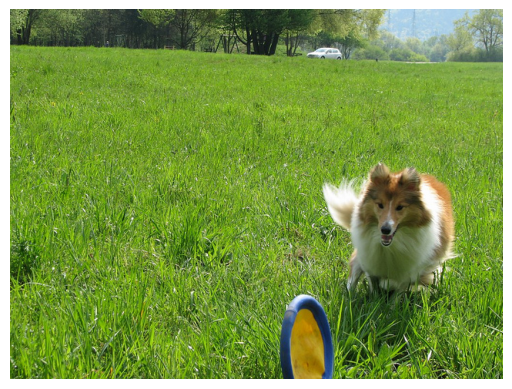

In [7]:
# Viweing an image from train2017

img_name = train_data[48]     # e.g. '000000391895.jpg'

img_path = os.path.join(train_path, img_name)

img_numpy_arr = plt.imread(img_path)
print('Image size: ', img_numpy_arr.shape)

plt.imshow(img_numpy_arr)
plt.axis('off')
plt.show()

## Checking Annotation data

In [8]:
annotation_path = os.path.join(data_path, 'annotations')

print(os.listdir(annotation_path))

['captions_train2017.json', 'captions_val2017.json', 'instances_train2017.json', 'instances_val2017.json', 'person_keypoints_train2017.json', 'person_keypoints_val2017.json']


In [ ]:
# Viewing json Training annotation file(captions_train2017.json) from the COCO dataset

train_ann_path = os.path.join(annotation_path, 'captions_train2017.json')

with open(train_ann_path) as file:
    train_ann = json.load(file)   # .load() converts a JSON file into native Python data structures(list, dictonary(here), str, bool, etc)

print(train_ann.keys())

dict_keys(['info', 'licenses', 'images', 'annotations'])


## Inside `captions_*.json` file — 

| Key | What it holds |
|---|---|
| `info` | Metadata about the dataset itself (version, description, year, contributor) — describes the *dataset*, not any image |
| `licenses` | A lookup list of licensing/attribution text (Creative Commons, etc.) for the source images |
| `images` | One entry per image: `id`, `file_name`, `height`, `width`, `coco_url`, `flickr_url`, `date_captured` |
| `annotations` | One entry per **caption**: `image_id` (links back to `images`), `id` (caption's own unique id), `caption` (the text) |

Out of these four keys, only `images` and `annotations` are used in CLIP model, cause we need image-text pair —
- We get image's name from 'images' file: `id → file_name` (file_name: the name of the file on disk) 
- and we get caption for an image from 'annotation' file: `image_id → caption text` (caption text: caption of an image).

In both the files the `id` and `image_id` are same, so we can use them to create a dataframe with Image-Text pair.


### `NOTE:` There are 118,287 images and 591,753 annotations

This isn't a bug — it's expected, and it's why the two are separate lists rather than one merged table:

- COCO deliberately collected **multiple independent captions per image** (different annotators describing the same photo)
- 591,753 annotations ÷ 118,287 images ≈ **5 captions per image on average**
- This is why an image like `106140` can show up twice in `annotations['annotations']` with different captions ("large passenger airplane" vs "GOL plane taking off") describing the same photo

This 1-image-to-many-captions structure is exactly why a `Dataset` class built on this data picks one caption at random per image per epoch — it lets you use the caption diversity as free data augmentation across epochs, rather than treating all 5 as identical duplicate rows.

In [10]:
# Viewing 'images' file

train_ann_images_df = pd.DataFrame(train_ann['images'])   # Converting dictonry (train_ann['images]) into DataFrame
train_ann_images_df.head()

,license,file_name,coco_url,height,width,date_captured,flickr_url,id
0,3,000000391895.jpg,http://images.cocodataset.org/train2017/000000...,360,640,2013-11-14 11:18:45,http://farm9.staticflickr.com/8186/8119368305_...,391895
1,4,000000522418.jpg,http://images.cocodataset.org/train2017/000000...,480,640,2013-11-14 11:38:44,http://farm1.staticflickr.com/1/127244861_ab0c...,522418
2,3,000000184613.jpg,http://images.cocodataset.org/train2017/000000...,336,500,2013-11-14 12:36:29,http://farm3.staticflickr.com/2169/2118578392_...,184613
3,3,000000318219.jpg,http://images.cocodataset.org/train2017/000000...,640,556,2013-11-14 13:02:53,http://farm5.staticflickr.com/4125/5094763076_...,318219
4,3,000000554625.jpg,http://images.cocodataset.org/train2017/000000...,640,426,2013-11-14 16:03:19,http://farm5.staticflickr.com/4086/5094162993_...,554625


In [11]:
# Viewing 'annotations' file

train_ann_annotations_df = pd.DataFrame(train_ann['annotations'])
train_ann_annotations_df.head()

,image_id,id,caption
0,203564,37,A bicycle replica with a clock as the front wh...
1,322141,49,A room with blue walls and a white sink and door.
2,16977,89,A car that seems to be parked illegally behind...
3,106140,98,A large passenger airplane flying through the ...
4,106140,101,There is a GOL plane taking off in a partly cl...


## Creating a Dataframe with image_name and caption

In [12]:
# Taking image name from 'images' (mentioned as file_name), and caption from 'annotation' (mentioned as caption). Both 
# have 'id' and 'image_id' as a common attribute in them


# Creating mapping from id to image name 
id_to_name = {}
for images_dict in train_ann['images']:
    
    img_id = images_dict['id']
    img_name = images_dict['file_name']

    id_to_name[img_id] = img_name

# Creating mapping from id to caption
id_to_caption = []
for annotation_dict in train_ann['annotations']:

    img_id = annotation_dict['image_id']
    img_caption = annotation_dict['caption']

    id_to_caption.append([img_id, img_caption])


# Now we have 5 caption for same image, so same image can appear 5 times with different caption. Since CLIP fundamentally 
# trains on pairs (image,text), we make 1 row = 1 positive image-caption pair

# Creating mapping from image_name to image_caption
image_to_caption = []
for i in range(len(id_to_caption)):
    id_val = id_to_caption[i][0]
    img_caption = id_to_caption[i][1]
    
    img_name = id_to_name[id_val]
    img_path = os.path.join(train_path, img_name)

    image_to_caption.append([img_path, img_caption])


# Creating a DataFrame with column: Image Path, Caption
train_df = pd.DataFrame(image_to_caption, columns = ['Img_Path', 'Caption'])

In [13]:
print('Total Number of Image-Caption pair: ', len(train_df))
print(train_df.columns.tolist())

Total Number of Image-Caption pair:  591753
['Img_Path', 'Caption']


In [14]:
train_df.head()

,Img_Path,Caption
0,D:\COCO2017\coco2017\train2017\000000203564.jpg,A bicycle replica with a clock as the front wh...
1,D:\COCO2017\coco2017\train2017\000000322141.jpg,A room with blue walls and a white sink and door.
2,D:\COCO2017\coco2017\train2017\000000016977.jpg,A car that seems to be parked illegally behind...
3,D:\COCO2017\coco2017\train2017\000000106140.jpg,A large passenger airplane flying through the ...
4,D:\COCO2017\coco2017\train2017\000000106140.jpg,There is a GOL plane taking off in a partly cl...


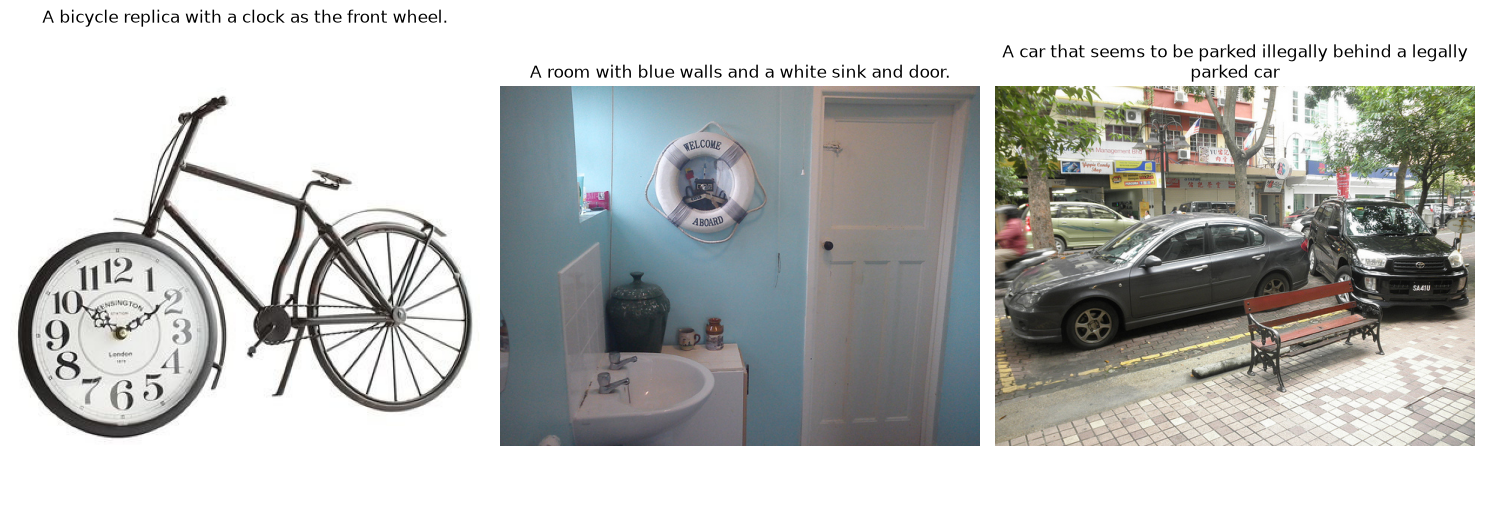

In [15]:
# Viewing Image-Text pairs

n_row = 1
n_col = 3

fig, axes = plt.subplots(n_row, n_col, figsize = (5*n_col, 5))

for i in range(n_col):
    img_path, caption = train_df.iloc[i]
    img = plt.imread(img_path)
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(caption, wrap = True)

plt.tight_layout()
plt.show()

## Saving the Image-Caption DataFrame for using in another notebooks

In [ ]:
csv_path = os.path.join(r"C:\Users\HARSH\OneDrive\Documents\VS Code Repos\CLIP model\Data", "ImagePath_caption.csv")

train_df.to_csv(csv_path, index = False)